# **Fase 3: Análisis de Errores y Simulación de 1.500 Partidas**
## **Auditoría de simetrías y validación empírica en torneo automatizado**

En este notebook auditamos los casos en que la predicción pura de `RandomForestClassifier` difiere de la etiqueta única del dataset (verificando cuántos corresponden a jugadas óptimas equivalentes por simetría) y ejecutamos **1.500 partidas simuladas** contra tres perfiles de adversario.

In [1]:
import random
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

datos = pd.read_csv(Path("../data/dataset_tres_en_raya.csv"))
rf = joblib.load(Path("../models/modelo_rf_tres_en_raya.joblib"))

LINEAS_GANADORAS = [
    (0, 1, 2), (3, 4, 5), (6, 7, 8),
    (0, 3, 6), (1, 4, 7), (2, 5, 8),
    (0, 4, 8), (2, 4, 6)
]

def verificar_ganador(b):
    for a, c, d in LINEAS_GANADORAS:
        if b[a] != 0 and b[a] == b[c] == b[d]:
            return b[a]
    return 0 if 0 not in b else None

def minimax(b, depth, is_max, alpha=-999, beta=999):
    w = verificar_ganador(b)
    if w == 1: return 10 - depth
    if w == -1: return depth - 10
    if w == 0: return 0
    if is_max:
        best = -999
        for i in range(9):
            if b[i] == 0:
                b[i] = 1
                best = max(best, minimax(b, depth + 1, False, alpha, beta))
                b[i] = 0
                alpha = max(alpha, best)
                if beta <= alpha: break
        return best
    else:
        best = 999
        for i in range(9):
            if b[i] == 0:
                b[i] = -1
                best = min(best, minimax(b, depth + 1, True, alpha, beta))
                b[i] = 0
                beta = min(beta, best)
                if beta <= alpha: break
        return best

def jugadas_optimas_equivalentes(tablero):
    evals = {}
    for i in range(9):
        if tablero[i] == 0:
            tablero[i] = 1
            evals[i] = minimax(tablero, 0, False)
            tablero[i] = 0
    max_score = max(evals.values())
    return {k for k, v in evals.items() if v == max_score}

print("Funciones de auditoría cargadas.")

Funciones de auditoría cargadas.


## **2. Auditoría de errores del modelo supervisado frente al oráculo Minimax**

Comparamos las predicciones de `RandomForestClassifier` sobre el conjunto completo de 2.423 estados para distinguir entre **jugadas óptimas equivalentes por simetría** y **errores reales subóptimos**.

In [2]:
X_all = datos[[f"celda_{i}" for i in range(9)]]
y_all = datos["jugada_optima"].values
preds = rf.predict(X_all)

discrepancias = 0
equivalentes_optimas = 0
errores_suboptimos = 0

for idx in range(len(datos)):
    if preds[idx] != y_all[idx]:
        discrepancias += 1
        optimas = jugadas_optimas_equivalentes(X_all.iloc[idx].tolist())
        if int(preds[idx]) in optimas:
            equivalentes_optimas += 1
        else:
            errores_suboptimos += 1

resumen_errores = pd.DataFrame([
    {"Categoría": "Coincidencia exacta con etiqueta principal", "Cantidad": len(datos) - discrepancias, "Porcentaje (%)": round((len(datos) - discrepancias)/len(datos)*100, 2)},
    {"Categoría": "Discrepancia equivalente óptima (simetría)", "Cantidad": equivalentes_optimas, "Porcentaje (%)": round(equivalentes_optimas/len(datos)*100, 2)},
    {"Categoría": "Error táctico subóptimo (RF puro)", "Cantidad": errores_suboptimos, "Porcentaje (%)": round(errores_suboptimos/len(datos)*100, 2)},
])
display(resumen_errores)

,Categoría,Cantidad,Porcentaje (%)
0,Coincidencia exacta con etiqueta principal,2332,96.24
1,Discrepancia equivalente óptima (simetría),26,1.07
2,Error táctico subóptimo (RF puro),65,2.68


## **3. Simulación automatizada de 1.500 partidas (500 por perfil de adversario)**

Evaluamos el agente integrado (donde Minimax filtra el conjunto de jugadas óptimas y Random Forest pondera probabilísticamente el desempate entre opciones equivalentes) frente a tres tipos de jugadores: **Aleatorio**, **Subóptimo (70 % óptimo / 30 % aleatorio)** y **Óptimo Perfecto**.

,Perfil de Oponente,Partidas,Victorias IA,Empates,Derrotas IA,Tasa No-Derrota (%)
0,Aleatorio,500,452,48,0,100.0
1,Subóptimo (70% óptimo),500,223,277,0,100.0
2,Óptimo Perfecto,500,0,500,0,100.0


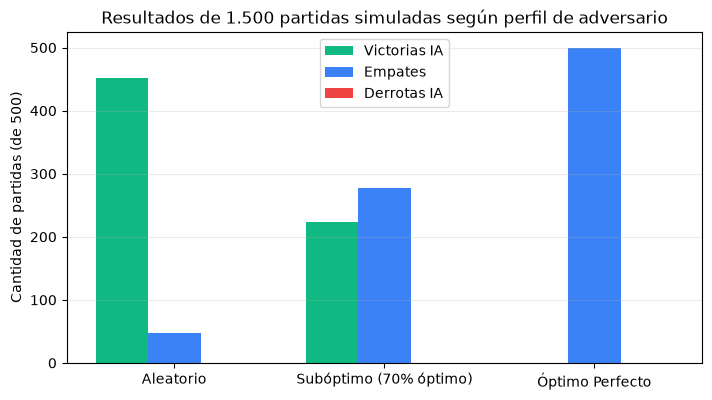

In [3]:
COLS_X = [f"celda_{i}" for i in range(9)]

def elegir_jugada_agente(tablero):
    optimas = list(jugadas_optimas_equivalentes(tablero))
    if len(optimas) == 1:
        return optimas[0]
    probs = rf.predict_proba(pd.DataFrame([tablero], columns=COLS_X))[0]
    clases = list(rf.classes_)
    pesos = [max(float(probs[clases.index(m)]) if m in clases else 0.05, 0.05) for m in optimas]
    return random.choices(optimas, weights=pesos, k=1)[0]

random.seed(SEMILLA)
resultados_sim = []

for perfil in ["Aleatorio", "Subóptimo (70% óptimo)", "Óptimo Perfecto"]:
    victorias, empates, derrotas = 0, 0, 0
    for partida in range(500):
        b = [0] * 9
        turno = 1 if partida % 2 == 0 else -1
        while True:
            res = verificar_ganador(b)
            if res is not None:
                if res == 1: victorias += 1
                elif res == 0: empates += 1
                else: derrotas += 1
                break
            if turno == 1:
                mv = elegir_jugada_agente(b)
                b[mv] = 1
            else:
                libres = [i for i in range(9) if b[i] == 0]
                if perfil == "Aleatorio":
                    mv = random.choice(libres)
                elif perfil == "Subóptimo (70% óptimo)":
                    mv = elegir_jugada_agente([-x for x in b]) if random.random() < 0.70 else random.choice(libres)
                else:
                    mv = elegir_jugada_agente([-x for x in b])
                b[mv] = -1
            turno = -turno
    resultados_sim.append({
        "Perfil de Oponente": perfil,
        "Partidas": 500,
        "Victorias IA": victorias,
        "Empates": empates,
        "Derrotas IA": derrotas,
        "Tasa No-Derrota (%)": round((victorias + empates) / 500 * 100, 2)
    })

df_sim = pd.DataFrame(resultados_sim)
display(df_sim)

fig, ax = plt.subplots(figsize=(8.2, 4.3))
x = np.arange(len(df_sim))
w = 0.25
ax.bar(x - w, df_sim["Victorias IA"], width=w, label="Victorias IA", color="#10B981")
ax.bar(x, df_sim["Empates"], width=w, label="Empates", color="#3B82F6")
ax.bar(x + w, df_sim["Derrotas IA"], width=w, label="Derrotas IA", color="#EF4444")
ax.set_xticks(x)
ax.set_xticklabels(df_sim["Perfil de Oponente"])
ax.set(title="Resultados de 1.500 partidas simuladas según perfil de adversario", ylabel="Cantidad de partidas (de 500)")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.savefig("../evidencias/fig2_simulacion_1500.png", bbox_inches="tight", dpi=150)
plt.show()